### 1. Configuración del Entorno y Verificación de la GPU

In [ ]:
import os
import sys

# Localizamos dónde tiene Conda escondidos los archivos de la gráficaRTX 5060
ruta_cuda = os.path.join(sys.prefix, 'Library', 'bin')

# Forzamos a Windows y a VS Code a meter esta ruta en su sistema principal
os.environ['PATH'] = ruta_cuda + os.pathsep + os.environ['PATH']

# importamos TensorFlow 
import tensorflow as tf

print("¿TensorFlow detecta la GPU?:", tf.test.is_built_with_cuda())
print("Dispositivos GPU disponibles:", tf.config.list_physical_devices('GPU'))

¿TensorFlow detecta la GPU?: True
Dispositivos GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


: 

: 

### 2. Importación de Librerías Principales

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage

: 

: 

### 3. Carga y Exploración del Dataset (ModelNet10 Volumétrico)

In [ ]:

# Carga y Preparación de Datos (ModelNet10)

import numpy as np

# Ponemos el nombre exacto del archivo que tenemos descargado
ruta_dataset = 'modelnet10_voxelized_32.npz' 

print("Cargando el dataset ModelNet10...")
datos = np.load(ruta_dataset)

# Extraemos las variables (este archivo en concreto usa la Y mayúscula)
X_train = datos['X_train']
X_test = datos['X_test']
y_train = datos['Y_train']
y_test = datos['Y_test']

# Las 10 categorías de ModelNet10 en orden
clases_modelnet = ['bathtub', 'bed', 'chair', 'desk', 'dresser', 
                   'monitor', 'night_stand', 'sofa', 'table', 'toilet']

# Añadimos la dimensión del "canal" al final para que Keras lo entienda -> (32, 32, 32, 1)
X_train = np.expand_dims(X_train, -1).astype(np.float32)
X_test = np.expand_dims(X_test, -1).astype(np.float32)

print(f"Forma de los datos de Entrenamiento: {X_train.shape}")
print(f"Forma de los datos de Test: {X_test.shape}")

Cargando el dataset ModelNet10...
Forma de los datos de Entrenamiento: (3991, 32, 32, 32, 1)
Forma de los datos de Test: (908, 32, 32, 32, 1)


: 

: 

### 4. Reducción del Dataset (Subconjunto de 4 Clases)

In [ ]:

# Reducción del Dataset (Solo 4 Clases)

# Índices originales: 1 (bed), 2 (chair), 5 (monitor), 9 (toilet)
clases_elegidas = [1, 2, 5, 9]

# Filtramos los datos para quedarnos solo con esas 4 clases
mask_train = np.isin(y_train, clases_elegidas)
mask_test = np.isin(y_test, clases_elegidas)

X_train_sub = X_train[mask_train]
y_train_sub = y_train[mask_train]
X_test_sub = X_test[mask_test]
y_test_sub = y_test[mask_test]

# Re-mapeamos las etiquetas para que sean 0, 1, 2, 3 (evita errores en las gráficas luego)
mapa_etiquetas = {vieja: nueva for nueva, vieja in enumerate(clases_elegidas)}
y_train_sub = np.array([mapa_etiquetas[y] for y in y_train_sub])
y_test_sub = np.array([mapa_etiquetas[y] for y in y_test_sub])

# Guardamos los nuevos nombres
nombres_clases_sub = [clases_modelnet[i] for i in clases_elegidas]

print(f"Dataset reducido con éxito a las clases: {nombres_clases_sub}")
print(f"Nuevos datos de Entrenamiento: {X_train_sub.shape[0]} objetos")

Dataset reducido con éxito a las clases: ['bed', 'chair', 'monitor', 'toilet']
Nuevos datos de Entrenamiento: 2213 objetos


: 

: 

### 5. Definición de la Arquitectura del Encoder 3D (con Dropout)

In [ ]:

# Arquitectura del Encoder Ampliado (32x32x32) con DROPOUT

from tensorflow.keras import layers
import tensorflow as tf

def build_encoder(latent_dim=256):
    encoder_inputs = tf.keras.Input(shape=(32, 32, 32, 1))
    
    # Reducciones sucesivas del cubo 3D con Dropout para evitar overfitting
    x = layers.Conv3D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs) # Baja a 16x16x16
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3D(64, 3, activation="relu", strides=2, padding="same")(x)              # Baja a 8x8x8
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3D(128, 3, activation="relu", strides=2, padding="same")(x)             # Baja a 4x4x4
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3D(256, 3, activation="relu", strides=2, padding="same")(x)             # Baja a 2x2x2
    x = layers.Dropout(0.3)(x)
    
    # Guardamos esta forma geométrica para decírsela al Decoder luego
    shape_before_flattening = tf.keras.backend.int_shape(x)[1:]
    
    # Aplastamos el cubo a un vector plano
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    
    # Coordenadas MMD / KL
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    
    # Función para generar la "niebla" de incertidumbre alrededor del punto
    def sampling(args):
        z_mean, z_log_var = args
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

    z = layers.Lambda(sampling, name="z")([z_mean, z_log_var])
    
    encoder = tf.keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
    return encoder, shape_before_flattening

print("Función del Encoder lista.")

Función del Encoder lista.


: 

: 

### 6. Definición de la Arquitectura del Decoder 3D

In [ ]:

# Arquitectura del Decoder Ampliado (32x32x32) con dropout

import numpy as np

def build_decoder(shape_before_flattening, latent_dim=256):
    latent_inputs = tf.keras.Input(shape=(latent_dim,))
    
    # Calculamos cuántas neuronas necesitamos para volver a armar el mini-cubo de 2x2x2
    unflatten_dim = np.prod(shape_before_flattening)
    
    x = layers.Dense(unflatten_dim, activation="relu")(latent_inputs)
    x = layers.Dropout(0.3)(x)
    
    x = layers.Reshape(shape_before_flattening)(x) # Recuperamos el 2x2x2
    
    # Expansiones sucesivas con Dropout
    x = layers.Conv3DTranspose(256, 3, activation="relu", strides=2, padding="same")(x) # Sube a 4x4x4
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3DTranspose(128, 3, activation="relu", strides=2, padding="same")(x) # Sube a 8x8x8
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)  # Sube a 16x16x16
    x = layers.Dropout(0.3)(x)
    
    x = layers.Conv3DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)  # Sube a 32x32x32
    # No ponemos dropout justo antes de la salida para no llenar la predicción final de "agujeros"
    
    # Capa final para dejar los píxeles entre 0 y 1
    decoder_outputs = layers.Conv3DTranspose(1, 3, activation="sigmoid", padding="same")(x)
    
    decoder = tf.keras.Model(latent_inputs, decoder_outputs, name="decoder")
    return decoder

print("Función del Decoder lista.")

Función del Decoder lista.


: 

: 

### 7. Construcción del Modelo VAE 3D (Lógica de Entrenamiento Personalizada)

In [ ]:

# Clase VAE Clásica (KL Divergence) para ModelNet

class VAE3D(tf.keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta # Peso del KL (1.0 es el VAE estándar)
        
        # Monitores para Entrenamiento
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")
        
        # Monitores para Validación
        self.val_total_loss_tracker = tf.keras.metrics.Mean(name="val_loss")
        self.val_recon_loss_tracker = tf.keras.metrics.Mean(name="val_recon_loss")
        self.val_kl_loss_tracker = tf.keras.metrics.Mean(name="val_kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker,
                self.val_total_loss_tracker, self.val_recon_loss_tracker, self.val_kl_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple): data = data[0]
        
        with tf.GradientTape() as tape:
            # Pasamos por el Encoder
            z_mean, z_log_var, z = self.encoder(data)
            
            # Reconstruimos con el Decoder
            reconstruccion = self.decoder(z)
            
            # Pérdida de Reconstrucción (Vóxeles 32x32x32)
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruccion), axis=(1, 2, 3))
            )
            
            # Pérdida KL (Fuerza a la distribución normal)
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            
            # Pérdida Total
            total_loss = recon_loss + (self.beta * kl_loss)
            
        # Aplicamos los gradientes
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        
        # Actualizamos monitores
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        
        return {
            "loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        if isinstance(data, tuple): data = data[0]
        
        z_mean, z_log_var, z = self.encoder(data)
        reconstruccion = self.decoder(z)
        
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruccion), axis=(1, 2, 3))
        )
        kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
        kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
        total_loss = recon_loss + (self.beta * kl_loss)
        
        self.val_total_loss_tracker.update_state(total_loss)
        self.val_recon_loss_tracker.update_state(recon_loss)
        self.val_kl_loss_tracker.update_state(kl_loss)
        
        return {
            "loss": self.val_total_loss_tracker.result(),
            "recon_loss": self.val_recon_loss_tracker.result(),
            "kl_loss": self.val_kl_loss_tracker.result(),
        }

    def call(self, inputs):
        _, _, z = self.encoder(inputs)
        return self.decoder(z)

: 

: 

### 8. Callback para la Visualización de Reconstrucciones en Tiempo Real

In [ ]:
# Ensamblaje y Entrenamiento (VAE Clásico KL) con EARLY STOPPING

from tensorflow.keras.callbacks import EarlyStopping, Callback
from IPython.display import clear_output
import matplotlib.pyplot as plt

# Visor HD para ver cómo aprende el modelo a realizar las reconstrucciones
class VisorReconstruccionModelNet(Callback):
    def __init__(self, datos_prueba, etiquetas, nombres_clases, num_ejemplos=4):
        super().__init__()
        self.datos_prueba = datos_prueba
        self.etiquetas = etiquetas
        self.nombres_clases = nombres_clases
        self.num_ejemplos = num_ejemplos
        
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 5 != 0: return # Dibuja cada 5 épocas
        
        clear_output(wait=True)
        print(f"\nReconstrucciones tras {epoch + 1} épocas")
        recon = self.model.predict(self.datos_prueba[:self.num_ejemplos], verbose=0)
        
        fig = plt.figure(figsize=(16, 8))
        for i in range(self.num_ejemplos):
            ax1 = fig.add_subplot(2, self.num_ejemplos, i + 1, projection='3d')
            ax1.voxels(self.datos_prueba[i,:,:,:,0] > 0.5, facecolors='#1f77b4', edgecolor=(0,0,0,0.1), alpha=0.5)
            nombre = self.nombres_clases[int(self.etiquetas[i])]
            ax1.set_title(f"Original ({nombre})")
            ax1.view_init(elev=30, azim=-60)
            ax1.axis('off')
            
            ax2 = fig.add_subplot(2, self.num_ejemplos, i + self.num_ejemplos + 1, projection='3d')
            # Umbral en 0.2 para ver las zonas difusas de los muebles
            ax2.voxels(recon[i,:,:,:,0] > 0.2, facecolors='teal', edgecolor=(0,0,0,0.1), alpha=0.8)
            ax2.set_title("Reconstrucción")
            ax2.view_init(elev=30, azim=-60)
            ax2.axis('off')
            
        plt.tight_layout()
        plt.show()

: 

: 

### 9. Ensamblaje, Compilación y Entrenamiento del Modelo (con Early Stopping)


--- Reconstrucciones tras 35 épocas ---


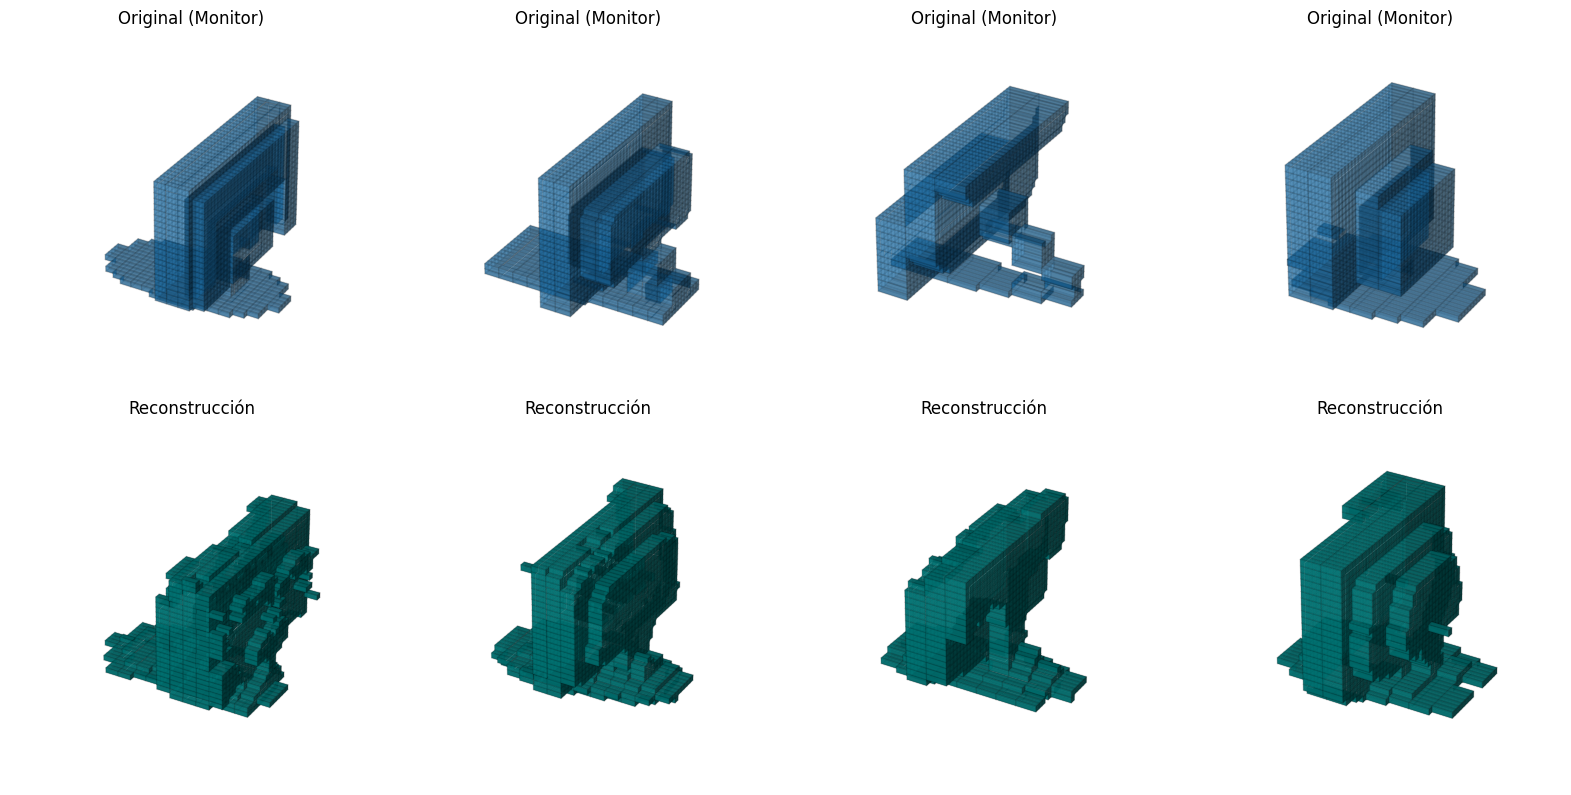

277/277 [==============================] - 214s 773ms/step - loss: 2593.5168 - recon_loss: 2327.3003 - kl_loss: 266.2162 - val_loss: 3950.2834 - val_recon_loss: 3691.0950 - val_kl_loss: 259.1882
Epoch 36/50
277/277 [==============================] - 182s 657ms/step - loss: 2553.8169 - recon_loss: 2286.8440 - kl_loss: 266.9720 - val_loss: 3913.4026 - val_recon_loss: 3640.1687 - val_kl_loss: 273.2341
Epoch 37/50
277/277 [==============================] - 188s 679ms/step - loss: 2489.5449 - recon_loss: 2218.3132 - kl_loss: 271.2323 - val_loss: 3832.1809 - val_recon_loss: 3574.5994 - val_kl_loss: 257.5820


In [12]:

# Ensamblamos usando el Encoder/Decoder de los bloques anteriores
encoder, shape_before = build_encoder(latent_dim=256)
decoder = build_decoder(shape_before, latent_dim=256)

# Usamos la clase VAE3D clásica
vae = VAE3D(encoder, decoder, beta=1.0)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002))

nombres_clases = {0: "Cama (Bed)", 1: "Silla (Chair)", 2: "Monitor", 3: "Inodoro (Toilet)"}

visor_callback = VisorReconstruccionModelNet(X_test_sub, y_test_sub, nombres_clases)

# Mantenemos el Early Stopping 
early_stopping = EarlyStopping(monitor='val_loss', min_delta=0.5, patience=5, restore_best_weights=True)

print("Iniciando entrenamiento del VAE Clásico con KL Divergence (32x32x32)...")
history = vae.fit(
    X_train_sub, X_train_sub,
    epochs=50,
    batch_size=8,
    validation_data=(X_test_sub, X_test_sub),
    callbacks=[visor_callback, early_stopping]
)

### 10. Análisis de la Evolución del Entrenamiento (Curvas de Aprendizaje)

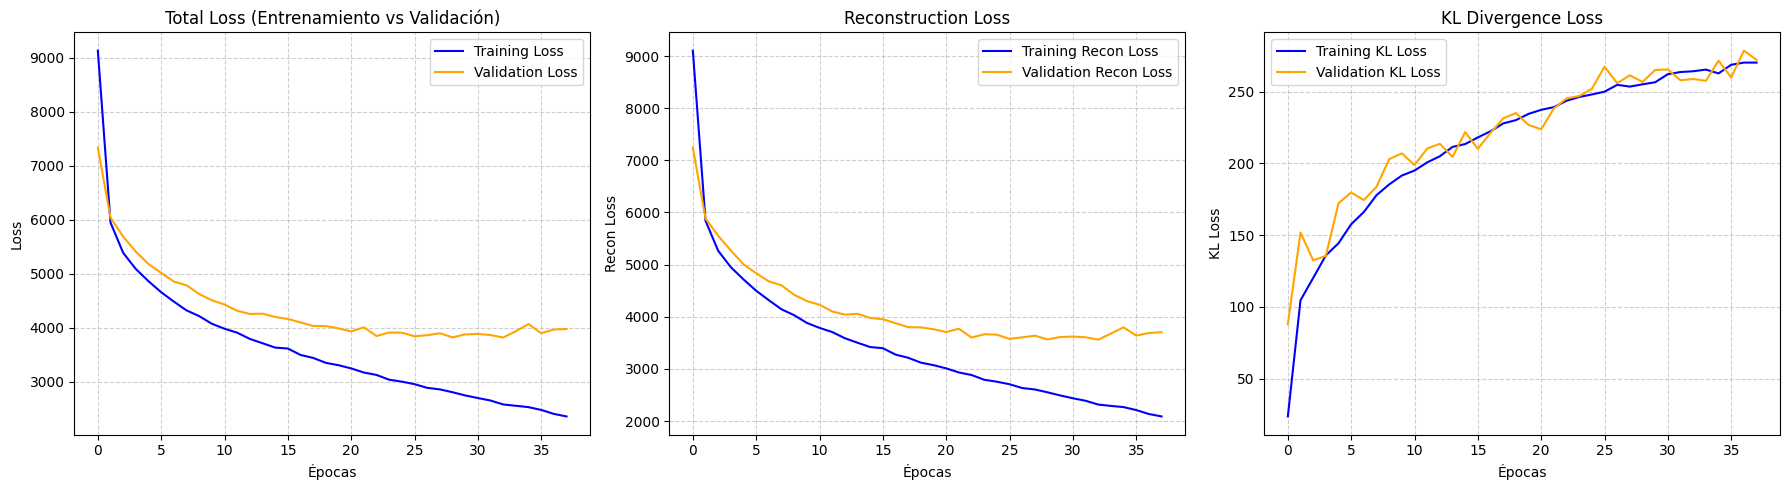

: 

: 

In [ ]:
import matplotlib.pyplot as plt

# Extraemos los datos del objeto history

hist = history.history

# Creamos una figura con 3 subgráficos en fila
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica del Loss Total
axes[0].plot(hist['loss'], label='Training Loss', color='blue')
axes[0].plot(hist['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title('Total Loss (Entrenamiento vs Validación)')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Gráfica del Reconstruction Loss
axes[1].plot(hist['recon_loss'], label='Training Recon Loss', color='blue')
axes[1].plot(hist['val_recon_loss'], label='Validation Recon Loss', color='orange')
axes[1].set_title('Reconstruction Loss')
axes[1].set_xlabel('Épocas')
axes[1].set_ylabel('Recon Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

# Gráfica del KL Divergence Loss
axes[2].plot(hist['kl_loss'], label='Training KL Loss', color='blue')
axes[2].plot(hist['val_kl_loss'], label='Validation KL Loss', color='orange')
axes[2].set_title('KL Divergence Loss')
axes[2].set_xlabel('Épocas')
axes[2].set_ylabel('KL Loss')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

# Ajustar el espaciado para que no se pisen los textos y mostrar
plt.tight_layout()
plt.show()

### Comparativa Directa Volumétrica: Muebles Originales vs. Reconstrucciones (WAE-MMD)

1/1 [==============================] - 0s 19ms/step


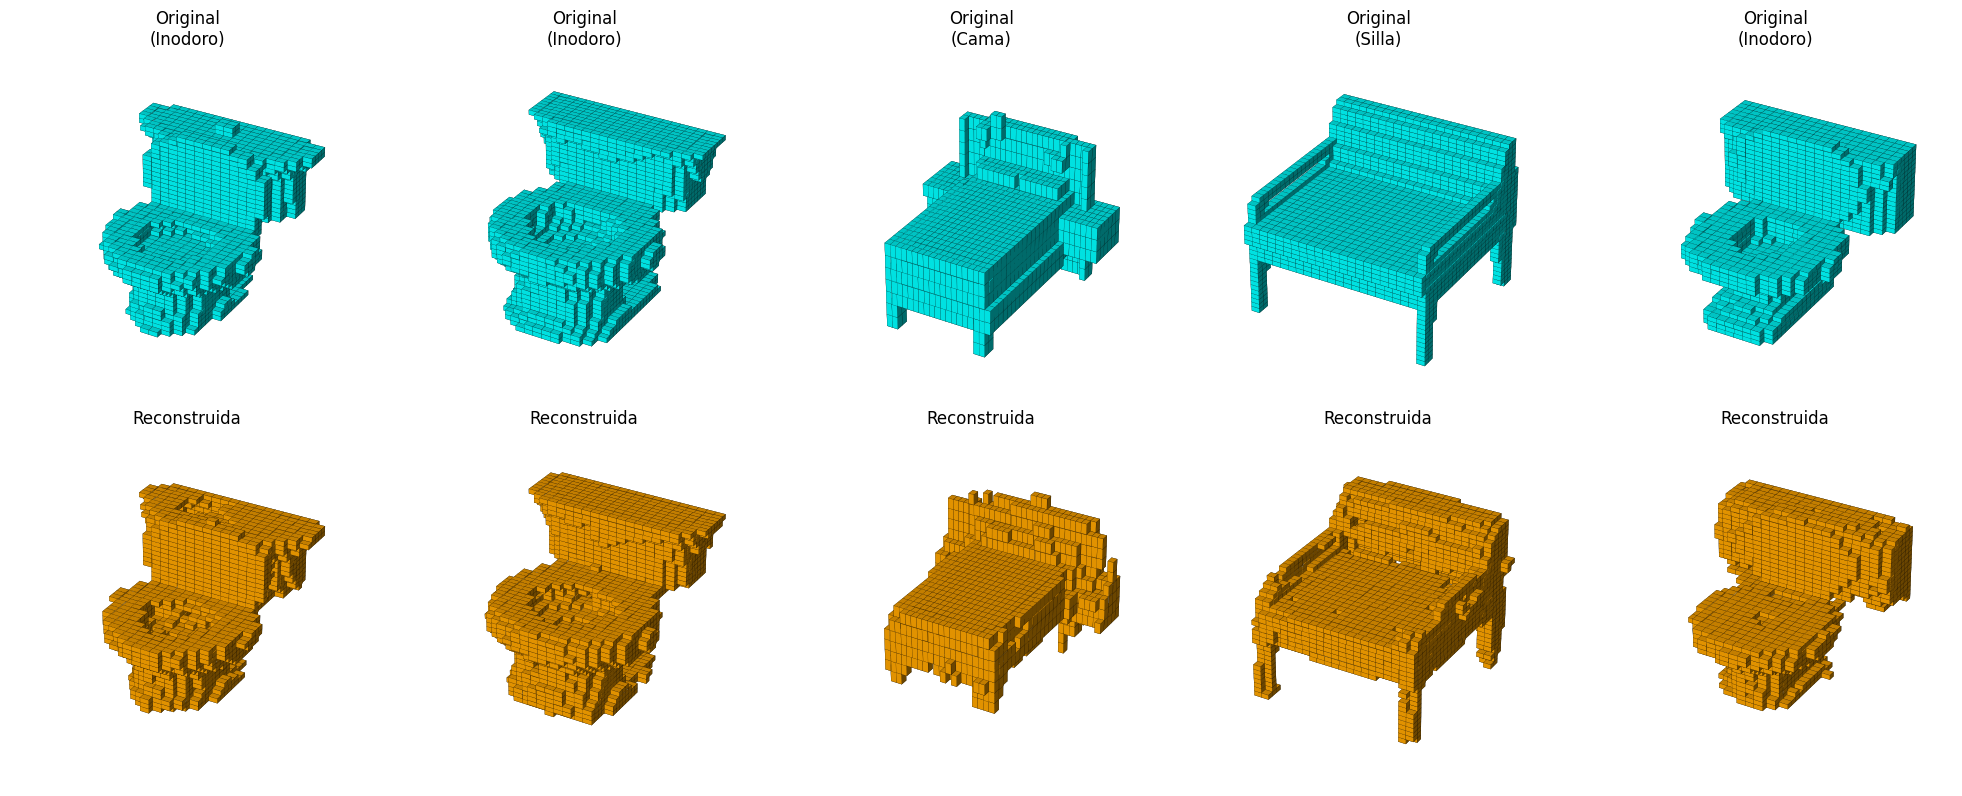

: 

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_imagenes = 5

# Generamos 5 índices aleatorios entre 0 y el total de imágenes de prueba
indices_aleatorios = np.random.choice(len(X_test_sub), size=n_imagenes, replace=False)

# Extraemos esas imágenes aleatorias y sus etiquetas
imagenes_prueba = X_test_sub[indices_aleatorios]
etiquetas_prueba = y_test_sub[indices_aleatorios] 

# Diccionario para saber qué mueble es (con las clases)
nombres_clases = {0: "Cama", 1: "Silla", 2: "Monitor", 3: "Inodoro"}

# Hacemos la predicción con el VAE
reconstrucciones = vae.predict(imagenes_prueba)

fig = plt.figure(figsize=(20, 8))

for i in range(n_imagenes):
    # Averiguamos el nombre del mueble actual para ponerlo en el título
    clase_id = etiquetas_prueba[i]
    nombre_mueble = nombres_clases.get(clase_id, f"Clase {clase_id}")

    # Mostrar imagen original 3D
    ax = fig.add_subplot(2, n_imagenes, i + 1, projection='3d')
    voxel_orig = imagenes_prueba[i][:, :, :, 0] > 0.5
    ax.voxels(voxel_orig, facecolors='cyan', edgecolor='k', linewidth=0.1)
    ax.set_title(f"Original\n({nombre_mueble})")
    ax.axis("off")

    # Mostrar imagen reconstruida 3D
    ax = fig.add_subplot(2, n_imagenes, i + 1 + n_imagenes, projection='3d')
    voxel_recon = reconstrucciones[i][:, :, :, 0] > 0.5
    ax.voxels(voxel_recon, facecolors='orange', edgecolor='k', linewidth=0.1)
    ax.set_title("Reconstruida")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Comparativa Directa Volumétrica: Muebles Originales vs. Reconstrucciones (WAE-MMD)

1/1 [==============================] - 0s 16ms/step


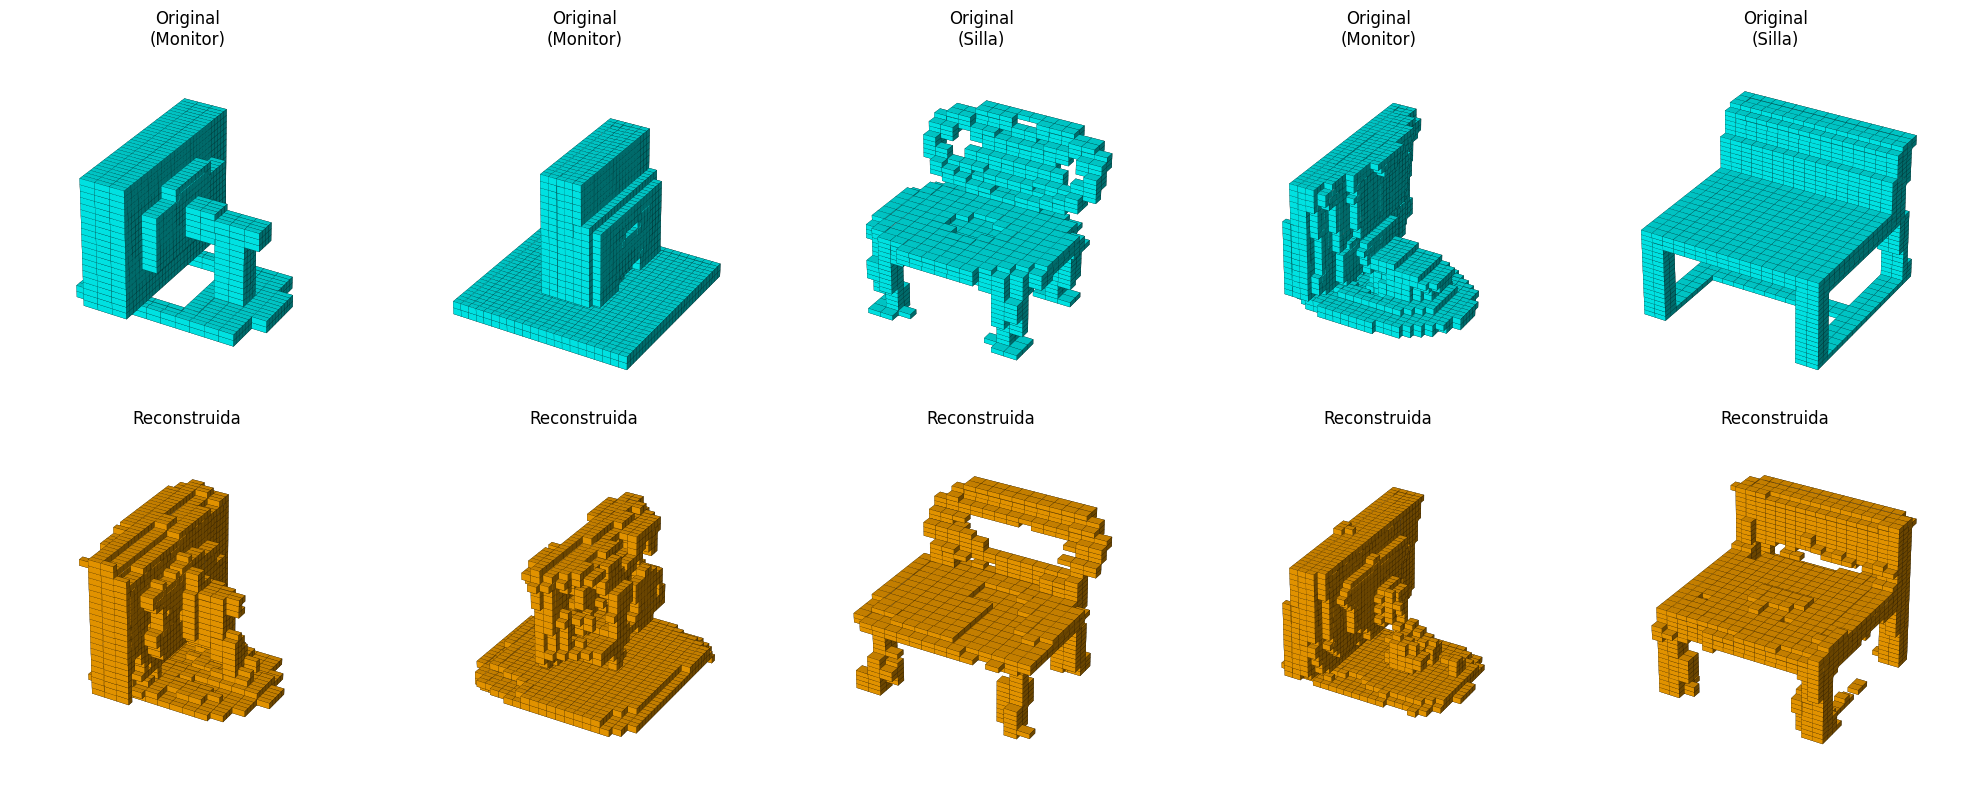

: 

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_imagenes = 5

# Generamos 5 índices aleatorios entre 0 y el total de imágenes de prueba
indices_aleatorios = np.random.choice(len(X_test_sub), size=n_imagenes, replace=False)

# Extraemos esas imágenes aleatorias y sus etiquetas
imagenes_prueba = X_test_sub[indices_aleatorios]
etiquetas_prueba = y_test_sub[indices_aleatorios] 

# Diccionario para saber qué mueble es (con las clases)
nombres_clases = {0: "Cama", 1: "Silla", 2: "Monitor", 3: "Inodoro"}

# Hacemos la predicción con el VAE
reconstrucciones = vae.predict(imagenes_prueba)

fig = plt.figure(figsize=(20, 8))

for i in range(n_imagenes):
    # Averiguamos el nombre del mueble actual para ponerlo en el título
    clase_id = etiquetas_prueba[i]
    nombre_mueble = nombres_clases.get(clase_id, f"Clase {clase_id}")

    # Mostrar imagen original 3D
    ax = fig.add_subplot(2, n_imagenes, i + 1, projection='3d')
    voxel_orig = imagenes_prueba[i][:, :, :, 0] > 0.5
    ax.voxels(voxel_orig, facecolors='cyan', edgecolor='k', linewidth=0.1)
    ax.set_title(f"Original\n({nombre_mueble})")
    ax.axis("off")

    # Mostrar imagen reconstruida 3D
    ax = fig.add_subplot(2, n_imagenes, i + 1 + n_imagenes, projection='3d')
    voxel_recon = reconstrucciones[i][:, :, :, 0] > 0.5
    ax.voxels(voxel_recon, facecolors='orange', edgecolor='k', linewidth=0.1)
    ax.set_title("Reconstruida")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 15. Generación Libre de Muebles 3D a partir de Ruido Prior (WAE-MMD)

1/1 [==============================] - 0s 105ms/step


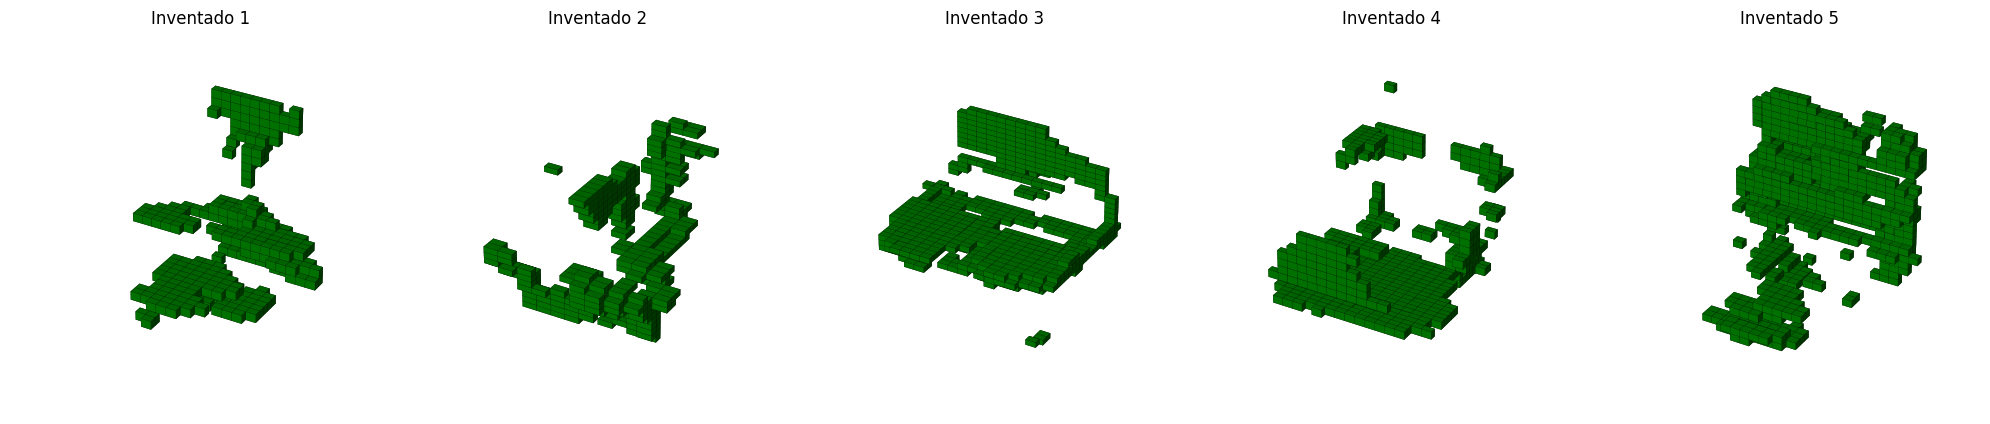

: 

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Definimos cuántos muebles nuevos queremos inventar
n_generar = 5


latent_dim = 256

# Creamos vectores aleatorios con una distribución normal estándar (media 0, varianza 1)
vectores_aleatorios = np.random.normal(0, 1, size=(n_generar, latent_dim))

# Pasamos estos vectores directamente al DECODER

muebles_generados = decoder.predict(vectores_aleatorios)

fig = plt.figure(figsize=(20, 5))
for i in range(n_generar):
    ax = fig.add_subplot(1, n_generar, i + 1, projection='3d')
    # Filtramos la predicción para dibujar solo los vóxeles con confianza > 50%
    voxel_gen = muebles_generados[i][:, :, :, 0] > 0.5
    ax.voxels(voxel_gen, facecolors='green', edgecolor='k', linewidth=0.1)
    ax.set_title(f"Inventado {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Metamorfosis Geométrica: Interpolación Lineal en el Espacio Latente (WAE-MMD)

1/1 [==============================] - 0s 14ms/step


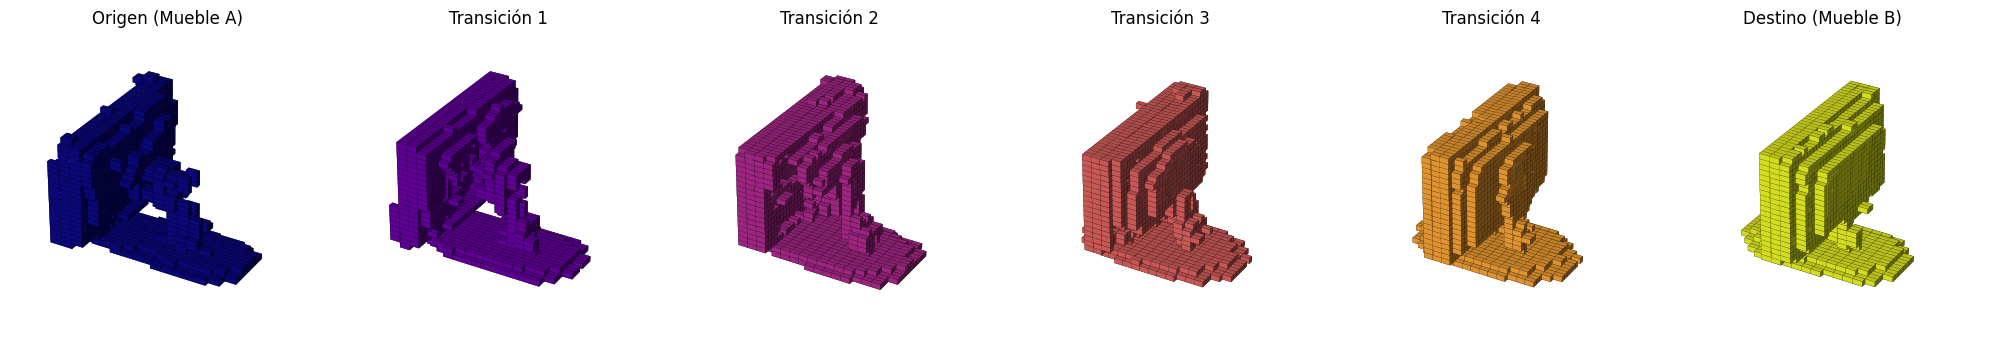

: 

: 

In [ ]:
# Seleccionamos dos muebles distintos del set de prueba
img_A = X_test_sub[50:51] # Mueble A
img_B = X_test_sub[5:6] # Mueble B

# Obtenemos sus vectores latentes usando el ENCODER

z_A = encoder.predict(img_A)[0] 
z_B = encoder.predict(img_B)[0]

# Definimos los pasos de la transición
pasos = 6
alphas = np.linspace(0, 1, pasos)

fig = plt.figure(figsize=(20, 5))

for i, alpha in enumerate(alphas):
    # Matemáticas de la interpolación lineal: mezclamos z_A y z_B
    z_interp = (1 - alpha) * z_A + alpha * z_B
    
    # Decodificamos el punto intermedio
    mueble_interp = decoder.predict(z_interp)
    
    # Dibujamos en 3D
    ax = fig.add_subplot(1, pasos, i + 1, projection='3d')
    voxel_interp = mueble_interp[0][:, :, :, 0] > 0.5
    
    # Degradado de color (de morado a amarillo)
    color = plt.cm.plasma(alpha) 
    
    ax.voxels(voxel_interp, facecolors=color, edgecolor='k', linewidth=0.1)
    
    if i == 0:
        ax.set_title("Origen (Mueble A)")
    elif i == pasos - 1:
        ax.set_title("Destino (Mueble B)")
    else:
        ax.set_title(f"Transición {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Metamorfosis Geométrica: Interpolación Lineal en el Espacio Latente (WAE-MMD)

1/1 [==============================] - 0s 13ms/step


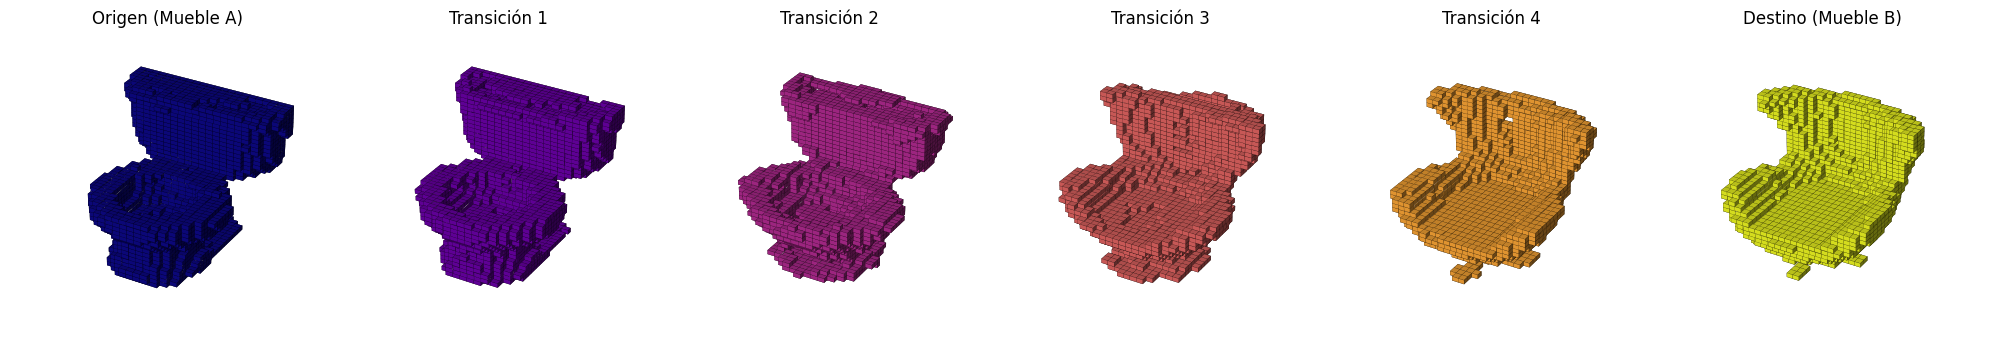

: 

: 

In [ ]:
#Seleccionamos dos muebles distintos del set de prueba
img_A = X_test_sub[150:151] # Mueble A
img_B = X_test_sub[220:221] # Mueble B

# Obtenemos sus vectores latentes usando el ENCODER

z_A = encoder.predict(img_A)[0] 
z_B = encoder.predict(img_B)[0]

# Definimos los pasos de la transición
pasos = 6
alphas = np.linspace(0, 1, pasos)

fig = plt.figure(figsize=(20, 5))

for i, alpha in enumerate(alphas):
    # Matemáticas de la interpolación lineal: mezclamos z_A y z_B
    z_interp = (1 - alpha) * z_A + alpha * z_B
    
    # Decodificamos el punto intermedio
    mueble_interp = decoder.predict(z_interp)
    
    # Dibujamos en 3D
    ax = fig.add_subplot(1, pasos, i + 1, projection='3d')
    voxel_interp = mueble_interp[0][:, :, :, 0] > 0.5
    
    # Degradado de color (de morado a amarillo)
    color = plt.cm.plasma(alpha) 
    
    ax.voxels(voxel_interp, facecolors=color, edgecolor='k', linewidth=0.1)
    
    if i == 0:
        ax.set_title("Origen (Mueble A)")
    elif i == pasos - 1:
        ax.set_title("Destino (Mueble B)")
    else:
        ax.set_title(f"Transición {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Proyección PCA del Espacio Latente (WAE-MMD)

13/13 [==============================] - 0s 9ms/step


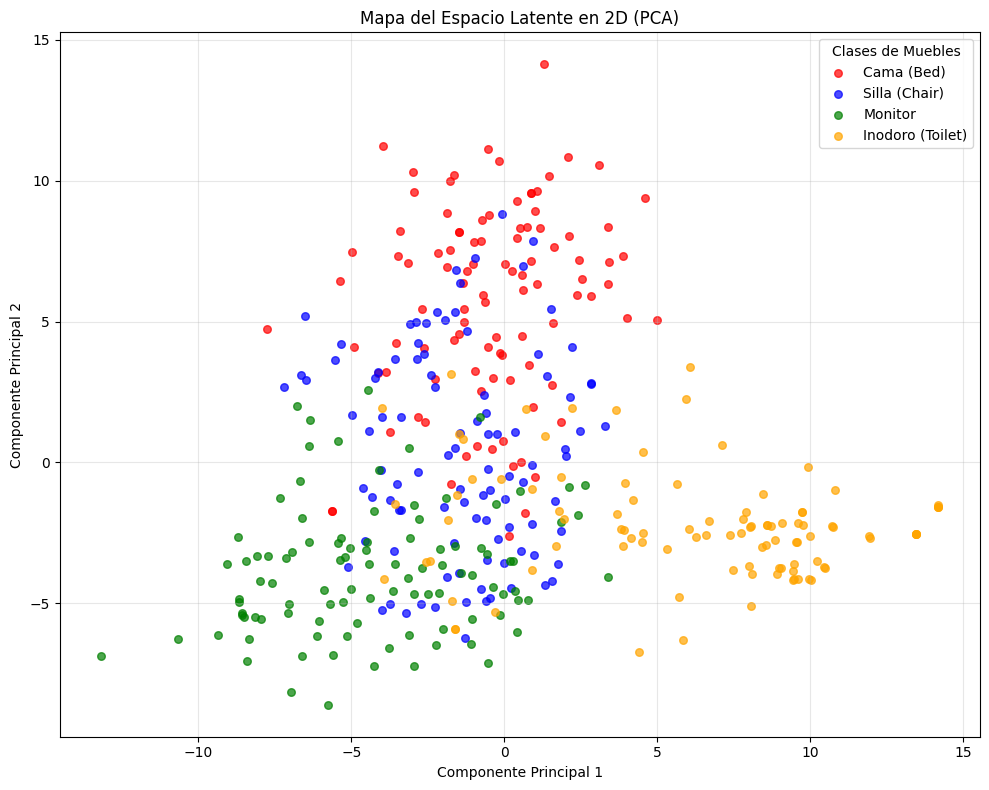

: 

: 

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Pasamos todas las imágenes de prueba por el Encoder

z_test = encoder.predict(X_test_sub)[0]

# PCA para aplastar la dimensión latente a 2D
pca = PCA(n_components=2)
z_test_2d = pca.fit_transform(z_test)

# Diccionario de nombres de clases
nombres_clases = {
    0: "Cama (Bed)",
    1: "Silla (Chair)",
    2: "Monitor",
    3: "Inodoro (Toilet)"
}

# Usamos directamente las etiquetas
y_labels = y_test_sub 

plt.figure(figsize=(10, 8))

# Colores fijos para las 4 clases
colores = ['red', 'blue', 'green', 'orange']

# np.unique detectará automáticamente que las clases son [1, 2, 5, 9]
clases_unicas = np.unique(y_labels)

# Dibujamos cada clase por separado para crear la leyenda
for i, clase_id in enumerate(clases_unicas):
    # Encontramos qué puntos pertenecen a esta clase
    indices = np.where(y_labels == clase_id)
    
    # Buscamos el nombre en el diccionario
    nombre = nombres_clases.get(clase_id, f"Clase {clase_id}")
    
    # Pintamos solo los puntos de esta clase
    plt.scatter(z_test_2d[indices, 0], z_test_2d[indices, 1], 
                c=colores[i], label=nombre, alpha=0.7, s=30)

# Títulos y Leyenda
plt.title("Mapa del Espacio Latente en 2D (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.legend(title="Clases de Muebles", loc="best")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Manifold 3D: Continuidad y Densidad del Espacio Latente (WAE-MMD)

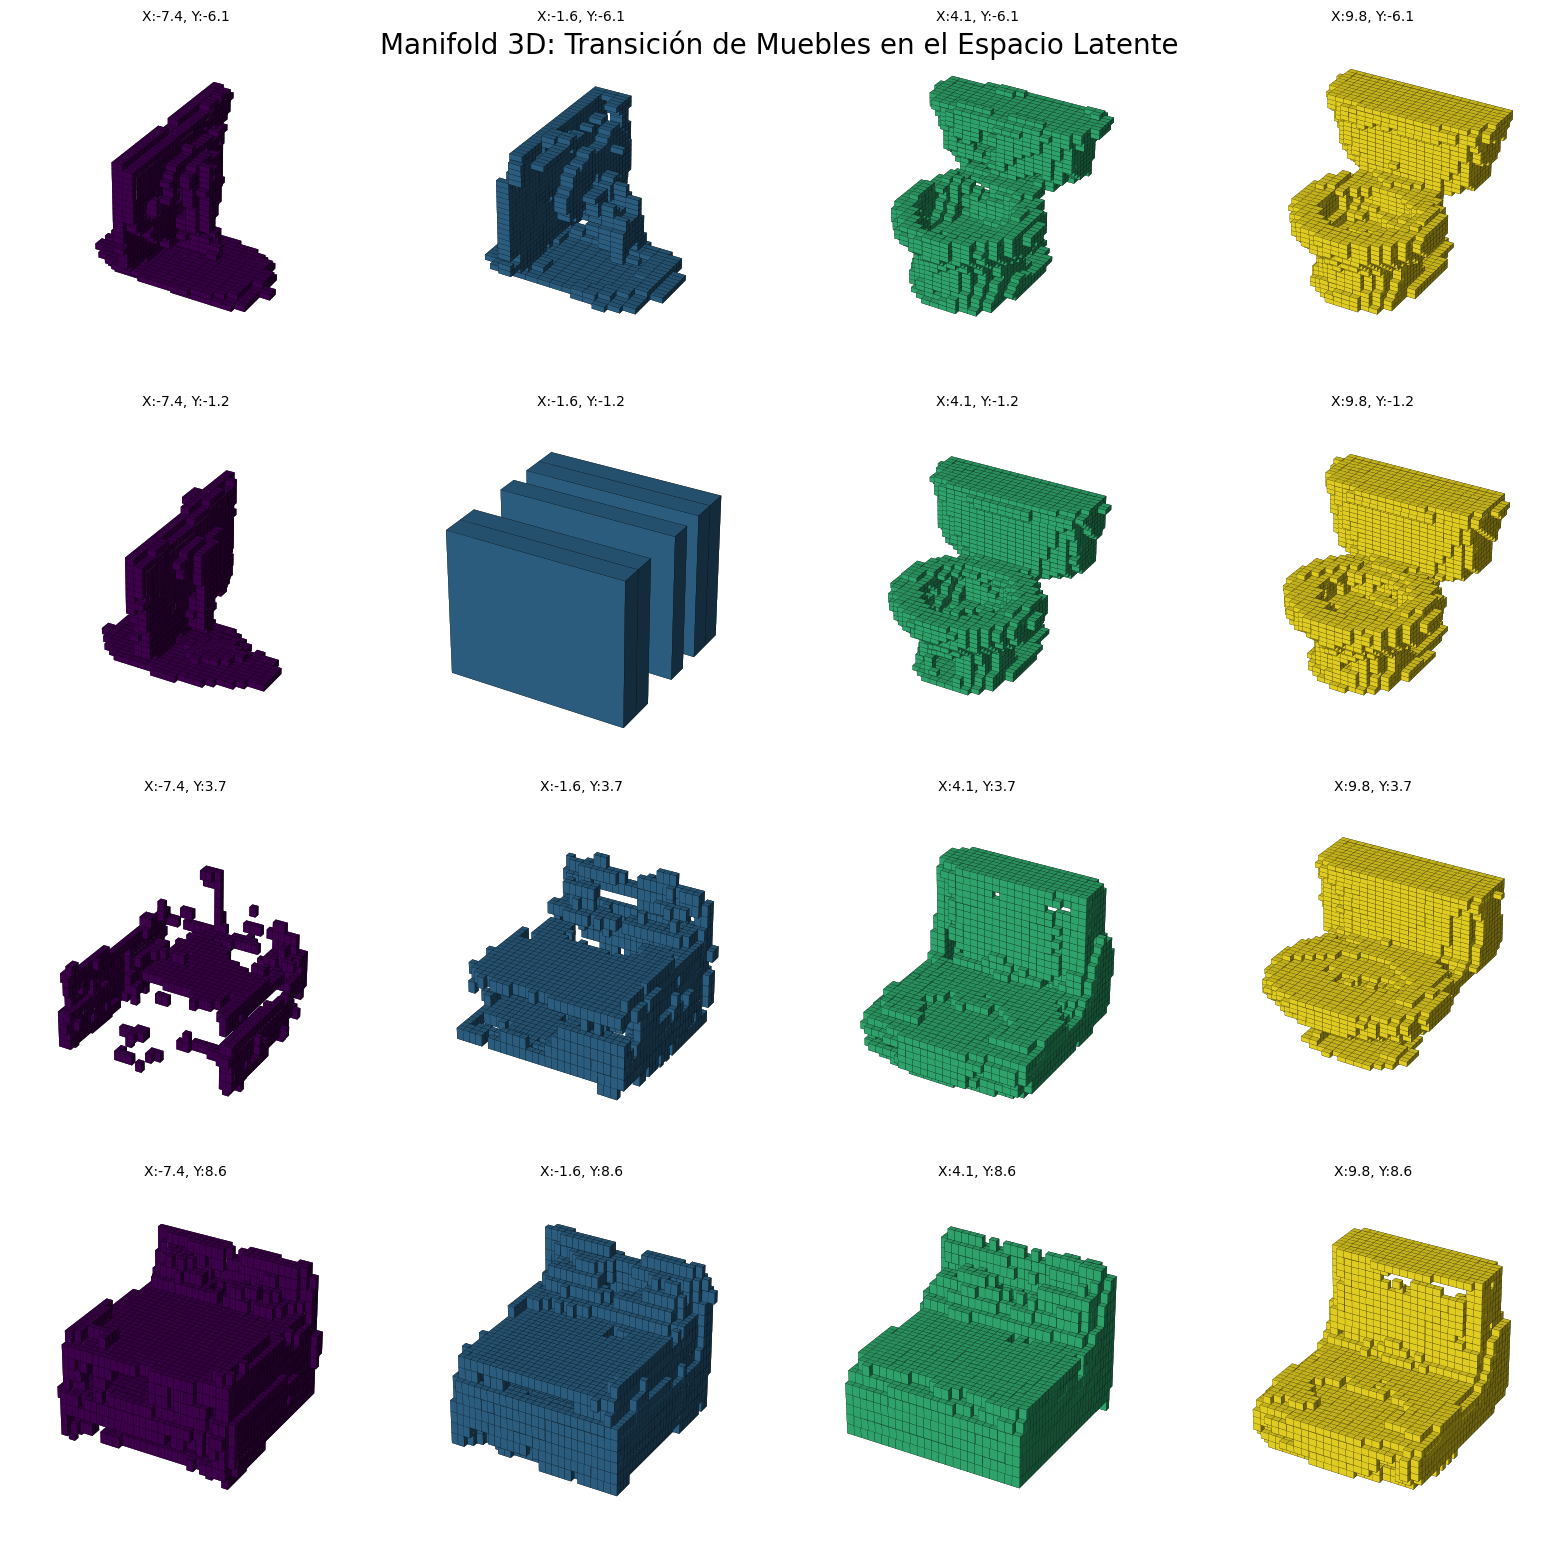

: 

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Tamaño de la cuadrícula (4x4 = 16 muebles en 3D).
n_grid = 4

# Calculamos los límites de la cuadrícula basándonos en tu mapa de puntos anterior
# (Usamos el percentil 5 y 95 para ignorar valores atípicos extremos)
min_x, max_x = np.percentile(z_test_2d[:, 0], [5, 95])
min_y, max_y = np.percentile(z_test_2d[:, 1], [5, 95])

# Creamos las coordenadas X e Y de nuestra cuadrícula
grid_x = np.linspace(min_x, max_x, n_grid)
grid_y = np.linspace(min_y, max_y, n_grid)

# Preparamos la figura
fig = plt.figure(figsize=(16, 16))

contador = 1
# Recorremos la cuadrícula fila por fila y columna por columna
for yi in grid_y:
    for xi in grid_x:
        # Cogemos la coordenada 2D de este punto de la cuadrícula
        punto_2d = np.array([[xi, yi]])
        
        # La "inflamos" a las 256 dimensiones de el espacio latente usando el PCA inverso
        z_256 = pca.inverse_transform(punto_2d)
        
        # Se la pasamos al DECODER para que construya el mueble físico
        mueble_generado = decoder.predict(z_256, verbose=0)
        
        # Lo preparamos para dibujarlo en 3D
        ax = fig.add_subplot(n_grid, n_grid, contador, projection='3d')
        voxel_gen = mueble_generado[0][:, :, :, 0] > 0.5
        
        # Le damos un color dinámico según su posición en X 
        color = plt.cm.viridis((xi - min_x) / (max_x - min_x))
        
        ax.voxels(voxel_gen, facecolors=color, edgecolor='k', linewidth=0.1)
        ax.set_title(f"X:{xi:.1f}, Y:{yi:.1f}", fontsize=10)
        ax.axis("off")
        
        contador += 1

plt.suptitle("Manifold 3D: Transición de Muebles en el Espacio Latente", fontsize=20, y=0.95)
plt.tight_layout()
plt.show()

## WAE

### Funciones Matemáticas para la Distancia MMD (Kernel IMQ en 3D)

In [13]:
import tensorflow as tf

def compute_kernel(x, y):
    x_size = tf.shape(x)[0]
    y_size = tf.shape(y)[0]
    dim = tf.cast(tf.shape(x)[1], tf.float32)

    # Expandimos dimensiones para que TensorFlow compare todos contra todos
    x = tf.expand_dims(x, 1) # (N, 1, d)
    y = tf.expand_dims(y, 0) # (1, M, d)
    
    tiled_x = tf.tile(x, [1, y_size, 1])
    tiled_y = tf.tile(y, [x_size, 1, 1])

    # Constante del Kernel IMQ (C = 2 * dim * 2)
    C = 2.0 * dim * 2.0
    
    # Calculamos la distancia al cuadrado ||x - y||^2
    dist_sq = tf.reduce_sum(tf.square(tiled_x - tiled_y), axis=-1)
    
    return C / (1e-7 + C + dist_sq)

def compute_mmd(z, z_prior):
    xx = compute_kernel(z, z)
    yy = compute_kernel(z_prior, z_prior)
    xy = compute_kernel(z, z_prior)

    batch_size = tf.cast(tf.shape(z)[0], tf.float32)
    
    # Eliminamos la diagonal para evitar sesgos (un punto comparado consigo mismo)
    xx_sum = tf.reduce_sum(xx) - tf.reduce_sum(tf.linalg.diag_part(xx))
    xx_val = xx_sum / (batch_size * (batch_size - 1.0))
    
    yy_sum = tf.reduce_sum(yy) - tf.reduce_sum(tf.linalg.diag_part(yy))
    yy_val = yy_sum / (batch_size * (batch_size - 1.0))
    
    xy_val = tf.reduce_mean(xy)

    return xx_val + yy_val - 2.0 * xy_val

print("Funciones MMD listas.")

Funciones MMD listas.


### Arquitectura del Encoder Determinista y Definición de la Clase WAE 3D

In [14]:
from tensorflow.keras import layers

def build_encoder_wae(latent_dim=256):
    encoder_inputs = tf.keras.Input(shape=(32, 32, 32, 1))
    
    # Reducciones con Dropout para evitar Overfitting
    x = layers.Conv3D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv3D(64, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv3D(128, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv3D(256, 3, activation="relu", strides=2, padding="same")(x)
    x = layers.Dropout(0.3)(x)
    
    shape_before_flattening = tf.keras.backend.int_shape(x)[1:]
    
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    
    # Salida directa Z determinista
    z = layers.Dense(latent_dim, name="z")(x)
    
    encoder = tf.keras.Model(encoder_inputs, z, name="encoder_wae")
    return encoder, shape_before_flattening

# Clase Keras para el WAE
class WAE3D(tf.keras.Model):
    def __init__(self, encoder, decoder, lmbda=10000.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.lmbda = lmbda # El hiperparámetro de peso para la MMD
        
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.mmd_loss_tracker = tf.keras.metrics.Mean(name="mmd_loss")
        self.val_total_loss_tracker = tf.keras.metrics.Mean(name="val_loss")
        self.val_recon_loss_tracker = tf.keras.metrics.Mean(name="val_recon_loss")
        self.val_mmd_loss_tracker = tf.keras.metrics.Mean(name="val_mmd_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.mmd_loss_tracker,
                self.val_total_loss_tracker, self.val_recon_loss_tracker, self.val_mmd_loss_tracker]

    def train_step(self, data):
        if isinstance(data, tuple): data = data[0]
        
        with tf.GradientTape() as tape:
            z = self.encoder(data)
            reconstruccion = self.decoder(z)
            
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruccion), axis=(1, 2, 3))
            )
            
            # Generamos ruido fresco para comparar distribuciones
            z_prior = tf.random.normal(tf.shape(z))
            mmd_val = compute_mmd(z, z_prior)
            mmd_loss = self.lmbda * mmd_val
            
            total_loss = recon_loss + mmd_loss
            
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        
        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.mmd_loss_tracker.update_state(mmd_val) # Guardamos la MMD pura para monitorizar
        
        return {"loss": self.total_loss_tracker.result(),
                "recon_loss": self.recon_loss_tracker.result(),
                "mmd": self.mmd_loss_tracker.result()}

    def test_step(self, data):
        if isinstance(data, tuple): data = data[0]
        
        z = self.encoder(data)
        reconstruccion = self.decoder(z)
        
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(tf.keras.losses.binary_crossentropy(data, reconstruccion), axis=(1, 2, 3))
        )
        z_prior = tf.random.normal(tf.shape(z))
        mmd_val = compute_mmd(z, z_prior)
        mmd_loss = self.lmbda * mmd_val
        
        total_loss = recon_loss + mmd_loss
        
        self.val_total_loss_tracker.update_state(total_loss)
        self.val_recon_loss_tracker.update_state(recon_loss)
        self.val_mmd_loss_tracker.update_state(mmd_val)
        
        return {"loss": self.val_total_loss_tracker.result(),
                "recon_loss": self.val_recon_loss_tracker.result(),
                "mmd": self.val_mmd_loss_tracker.result()}

    def call(self, inputs):
        z = self.encoder(inputs)
        return self.decoder(z)

print("Encoder WAE y Clase WAE3D listos.")

Encoder WAE y Clase WAE3D listos.


### Ensamblaje, Compilación y Entrenamiento del Modelo WAE-MMD


--- Reconstrucciones tras 5 épocas ---


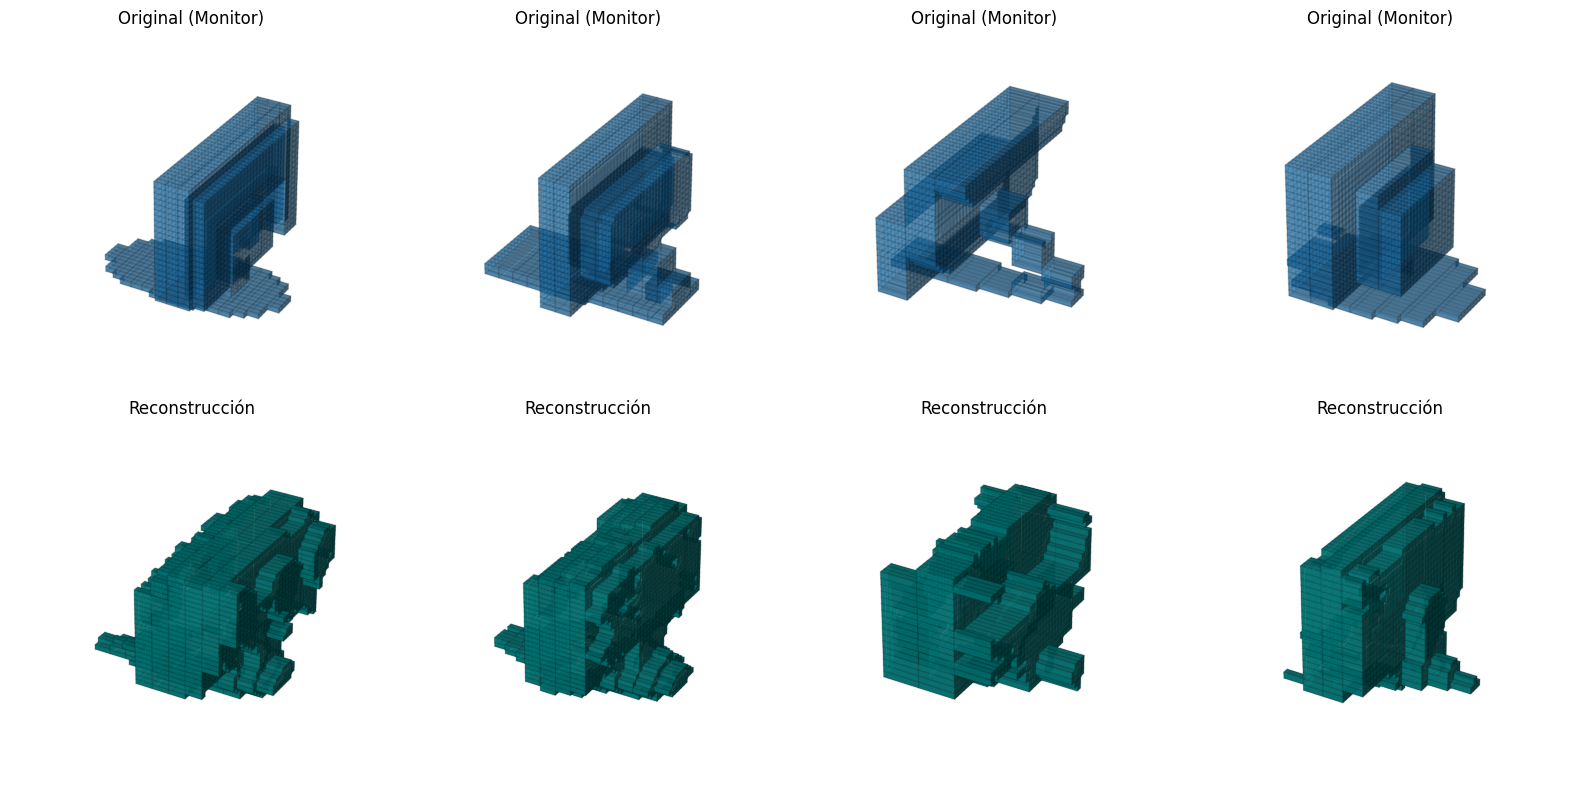

277/277 [==============================] - 206s 745ms/step - loss: 4617.8457 - recon_loss: 4492.2896 - mmd: 0.0133 - val_loss: 6193.5283 - val_recon_loss: 4922.4370 - val_mmd: 0.1271
Epoch 6/50
277/277 [==============================] - 179s 643ms/step - loss: 4391.4219 - recon_loss: 4275.9854 - mmd: 0.0127 - val_loss: 5683.8105 - val_recon_loss: 4636.0757 - val_mmd: 0.1048
Epoch 7/50
277/277 [==============================] - 182s 656ms/step - loss: 4186.2275 - recon_loss: 4084.5303 - mmd: 0.0115 - val_loss: 5525.8394 - val_recon_loss: 4465.0342 - val_mmd: 0.1061
Epoch 8/50
277/277 [==============================] - ETA: 0s - loss: 4020.2026 - recon_loss: 3933.0979 - mmd: 0.0103

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Construimos el Encoder WAE
encoder_wae, shape_before = build_encoder_wae(latent_dim=256)

# Reutilizamos la función de el Decoder original(ya lo tenías importado/definido de antes)
decoder_wae = build_decoder(shape_before, latent_dim=256)

# Ensamblamos el modelo WAE 3D (Fijamos lambda = 10000 como en el 2D)
wae = WAE3D(encoder_wae, decoder_wae, lmbda=10000.0)
wae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002))

# Callbacks: Early Stopping y nuestro visor de ModelNet
early_stopping_wae = EarlyStopping(monitor='val_loss', min_delta=0.5, patience=5, restore_best_weights=True)


visor_callback_wae = VisorReconstruccionModelNet(X_test_sub, y_test_sub, nombres_clases)

print("Iniciando entrenamiento del WAE-MMD (32x32x32)...")
historial_wae = wae.fit(
    X_train_sub, X_train_sub,
    epochs=50,
    batch_size=8,
    validation_data=(X_test_sub, X_test_sub),
    callbacks=[visor_callback_wae, early_stopping_wae]
)

### Análisis de la Evolución del Entrenamiento (Curvas WAE-MMD)

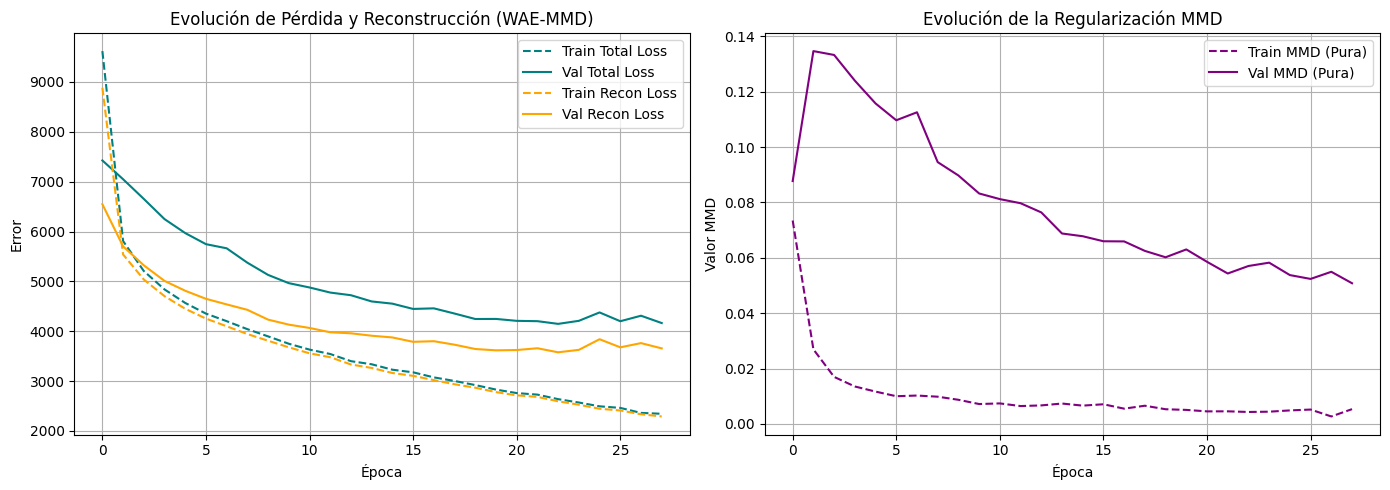

In [ ]:
import matplotlib.pyplot as plt

# Extraemos las métricas del historial del WAE
plt.figure(figsize=(14, 5))

# Pérdida Total y Reconstrucción
plt.subplot(1, 2, 1)
plt.plot(historial_wae.history['loss'], label='Train Total Loss', color='teal', linestyle='--')
plt.plot(historial_wae.history['val_loss'], label='Val Total Loss', color='teal')
plt.plot(historial_wae.history['recon_loss'], label='Train Recon Loss', color='orange', linestyle='--')
plt.plot(historial_wae.history['val_recon_loss'], label='Val Recon Loss', color='orange')
plt.title('Evolución de Pérdida y Reconstrucción (WAE-MMD)')
plt.xlabel('Época')
plt.ylabel('Error')
plt.legend()
plt.grid(True)

# Pérdida Regularizadora MMD
plt.subplot(1, 2, 2)
plt.plot(historial_wae.history['mmd'], label='Train MMD (Pura)', color='purple', linestyle='--')
plt.plot(historial_wae.history['val_mmd'], label='Val MMD (Pura)', color='purple')
plt.title('Evolución de la Regularización MMD')
plt.xlabel('Época')
plt.ylabel('Valor MMD')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("curva_modelnet_mmd.png", dpi=300) # Se guarda automáticamente
plt.show()

### Comparativa Directa Volumétrica: Originales vs. Reconstrucciones (WAE-MMD)

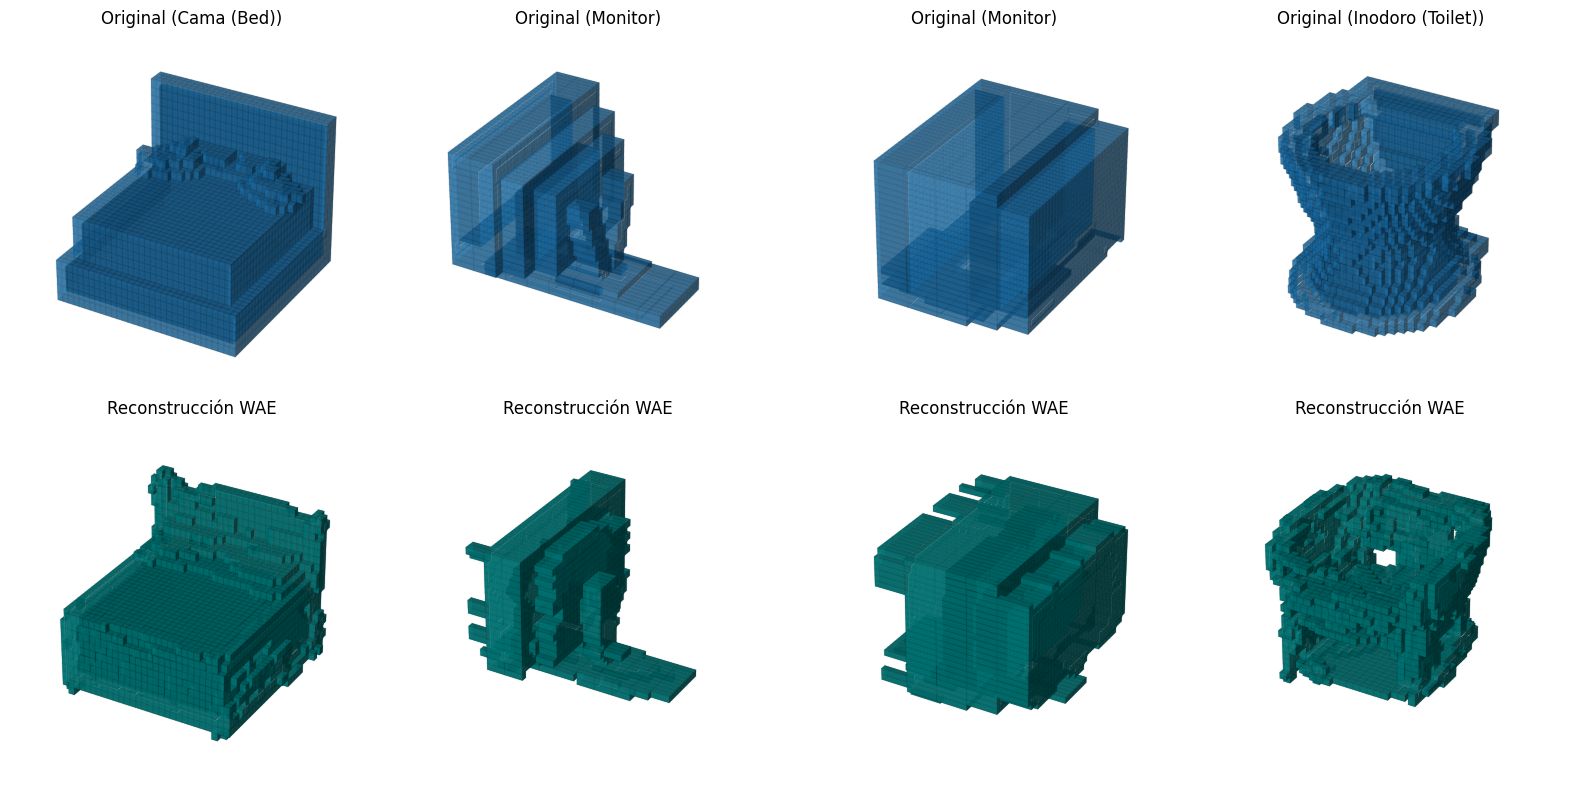

In [ ]:
import numpy as np

n_ejemplos = 4
indices = np.random.choice(len(X_test_sub), size=n_ejemplos, replace=False)
originales = X_test_sub[indices]
etiquetas = y_test_sub[indices]

# Nombres de las clases corregidos (0: Cama, 1: Silla, 2: Monitor, 3: Inodoro)
nombres_clases = {0: "Cama (Bed)", 1: "Silla (Chair)", 2: "Monitor", 3: "Inodoro (Toilet)"}

# Predicción del WAE
reconstruidos = wae.predict(originales, verbose=0)

fig = plt.figure(figsize=(16, 8))

for i in range(n_ejemplos):
    clase_id = int(etiquetas[i])
    nombre_mueble = nombres_clases.get(clase_id, f"Clase {clase_id}")
    
    # Mueble Original (Arriba)
    ax1 = fig.add_subplot(2, n_ejemplos, i + 1, projection='3d')
    voxel_orig = originales[i, :, :, :, 0] > 0.5
    ax1.voxels(voxel_orig, facecolors='#1f77b4', edgecolor=(0,0,0,0.05), alpha=0.6)
    ax1.set_title(f"Original ({nombre_mueble})")
    ax1.view_init(elev=30, azim=-60)
    ax1.axis('off')
    
    # Mueble Reconstruido WAE (Abajo)
    ax2 = fig.add_subplot(2, n_ejemplos, i + n_ejemplos + 1, projection='3d')
    voxel_recon = reconstruidos[i, :, :, :, 0] > 0.5  # Umbral estricto
    ax2.voxels(voxel_recon, facecolors='teal', edgecolor=(0,0,0,0.05), alpha=0.8)
    ax2.set_title("Reconstrucción WAE")
    ax2.view_init(elev=30, azim=-60)
    ax2.axis('off')

plt.tight_layout()
plt.savefig("comp_modelnet_mmd.png", dpi=300)
plt.show()

### Generación Libre de Muebles 3D a partir de Ruido Prior (WAE-MMD)

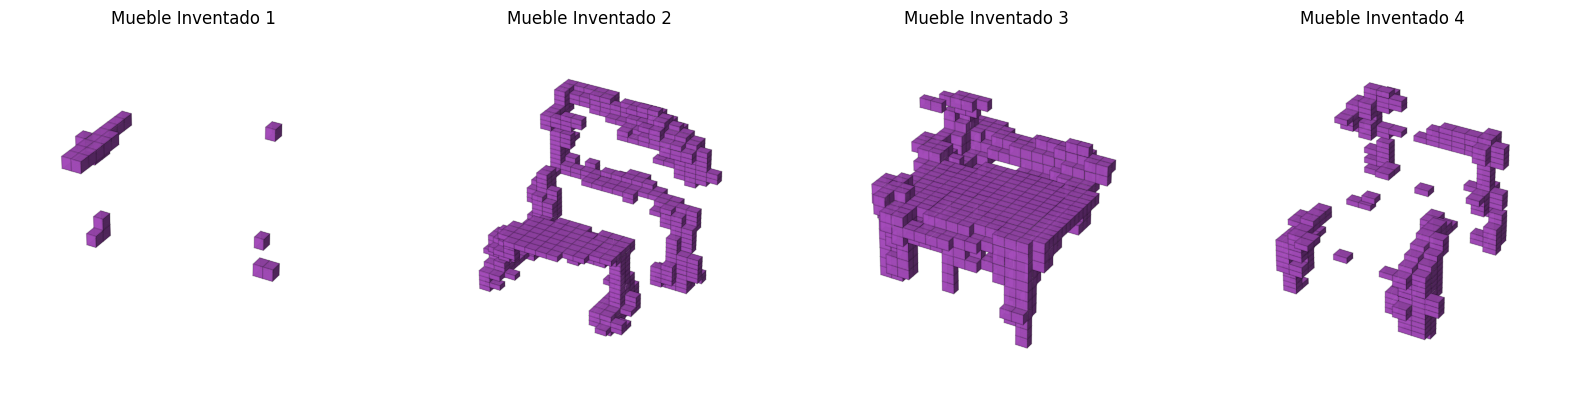

In [56]:
n_generados = 4
# Muestreamos de la distribución normal estándar (Dimensión latente = 256)
z_ruido = np.random.normal(0, 1, size=(n_generados, 256))

objetos_inventados = decoder_wae.predict(z_ruido, verbose=0)

fig = plt.figure(figsize=(16, 4))
for i in range(n_generados):
    ax = fig.add_subplot(1, n_generados, i + 1, projection='3d')
    voxel_gen = objetos_inventados[i, :, :, :, 0] > 0.5
    
    ax.voxels(voxel_gen, facecolors='mediumorchid', edgecolor=(0,0,0,0.1), alpha=0.9)
    ax.set_title(f"Mueble Inventado {i+1}")
    ax.view_init(elev=30, azim=-60)
    ax.axis('off')

plt.tight_layout()
plt.savefig("gen_modelnet_mmd.png", dpi=300)
plt.show()

### Metamorfosis Geométrica: Interpolación Lineal en el Espacio Latente (WAE-MMD)

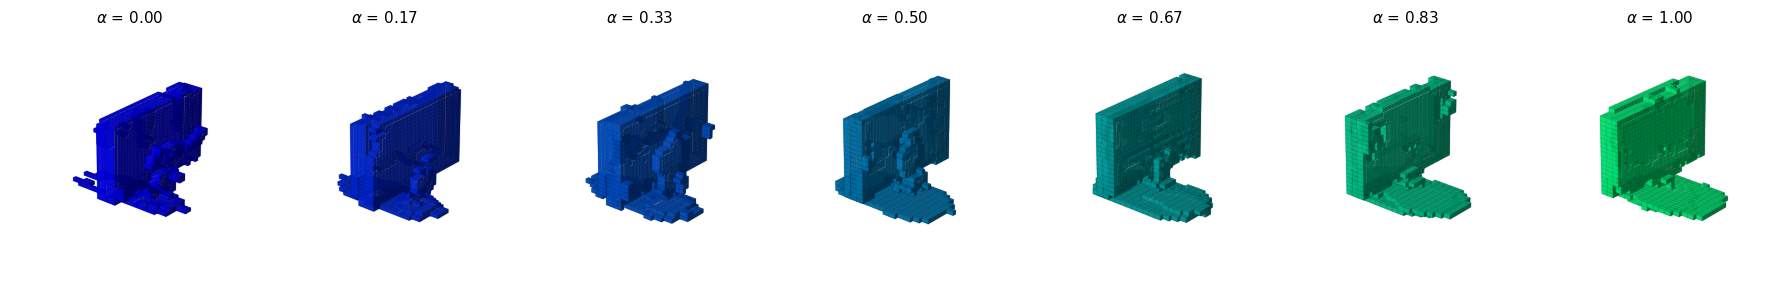

In [ ]:
# Tomamos dos objetos del test 
idx_a, idx_b = 0, 15
mueble_a = np.expand_dims(X_test_sub[idx_a], 0)
mueble_b = np.expand_dims(X_test_sub[idx_b], 0)

# Codificamos a sus vectores deterministas correspondientes
z_a = encoder_wae.predict(mueble_a, verbose=0)[0]
z_b = encoder_wae.predict(mueble_b, verbose=0)[0]

pasos = 7
alphas = np.linspace(0, 1, pasos)

fig = plt.figure(figsize=(18, 4))

for idx, alpha in enumerate(alphas):
    # Interpolación lineal clásica
    z_interp = (1 - alpha) * z_a + alpha * z_b
    z_interp = np.expand_dims(z_interp, 0)
    
    mueble_interp = decoder_wae.predict(z_interp, verbose=0)
    
    ax = fig.add_subplot(1, pasos, idx + 1, projection='3d')
    voxel_interp = mueble_interp[0, :, :, :, 0] > 0.5
    
    # Degradado de color de verde a azul según avanzamos en alpha
    color_interp = plt.cm.winter(alpha)
    
    ax.voxels(voxel_interp, facecolors=color_interp, edgecolor=(0,0,0,0.05), alpha=0.85)
    ax.set_title(f"$\\alpha$ = {alpha:.2f}", fontsize=11)
    ax.view_init(elev=25, azim=-50)
    ax.axis('off')

plt.tight_layout()
plt.savefig("inter_modelnet_mmd.png", dpi=300)
plt.show()

### Metamorfosis Geométrica: Interpolación Lineal en el Espacio Latente (WAE-MMD)

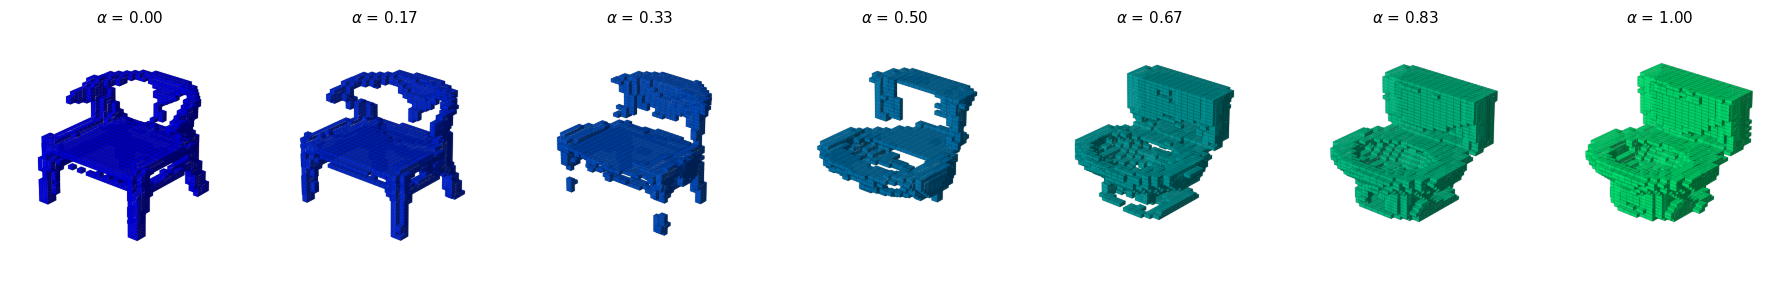

In [ ]:
# Tomamos dos objetos del test 
idx_a, idx_b = 230, 125
mueble_a = np.expand_dims(X_test_sub[idx_a], 0)
mueble_b = np.expand_dims(X_test_sub[idx_b], 0)

# Codificamos a sus vectores deterministas correspondientes
z_a = encoder_wae.predict(mueble_a, verbose=0)[0]
z_b = encoder_wae.predict(mueble_b, verbose=0)[0]

pasos = 7
alphas = np.linspace(0, 1, pasos)

fig = plt.figure(figsize=(18, 4))

for idx, alpha in enumerate(alphas):
    # Interpolación lineal clásica
    z_interp = (1 - alpha) * z_a + alpha * z_b
    z_interp = np.expand_dims(z_interp, 0)
    
    mueble_interp = decoder_wae.predict(z_interp, verbose=0)
    
    ax = fig.add_subplot(1, pasos, idx + 1, projection='3d')
    voxel_interp = mueble_interp[0, :, :, :, 0] > 0.5
    
    # Degradado de color de verde a azul según avanzamos en alpha
    color_interp = plt.cm.winter(alpha)
    
    ax.voxels(voxel_interp, facecolors=color_interp, edgecolor=(0,0,0,0.05), alpha=0.85)
    ax.set_title(f"$\\alpha$ = {alpha:.2f}", fontsize=11)
    ax.view_init(elev=25, azim=-50)
    ax.axis('off')

plt.tight_layout()
plt.savefig("inter_modelnet_mmd.png", dpi=300)
plt.show()

### Proyección PCA del Espacio Latente por Clases (WAE-MMD)

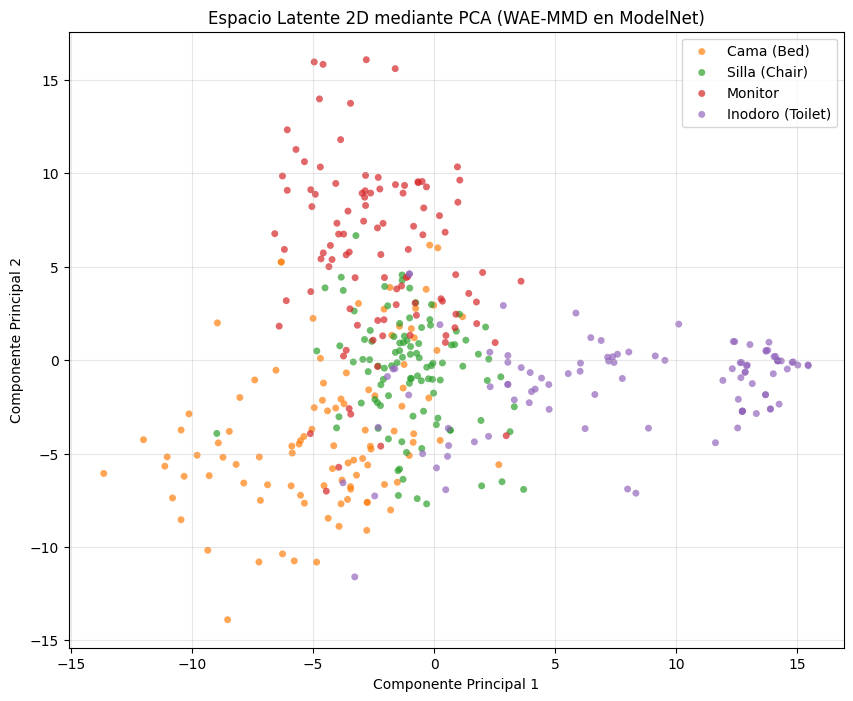

In [ ]:
from sklearn.decomposition import PCA

# Obtenemos las coordenadas latentes deterministas Z del WAE
z_test = encoder_wae.predict(X_test_sub, verbose=0)

# Reducimos con PCA a 2 componentes principales
pca_wae = PCA(n_components=2)
z_test_2d_wae = pca_wae.fit_transform(z_test)

# Graficamos por clases
plt.figure(figsize=(10, 8))
colores = ['#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
clases_id = [0, 1, 2, 3]
nombres_clases_lista = ["Cama (Bed)", "Silla (Chair)", "Monitor", "Inodoro (Toilet)"]

for idx, clase in enumerate(clases_id):
    mascara = (y_test_sub == clase)
    plt.scatter(z_test_2d_wae[mascara, 0], z_test_2d_wae[mascara, 1], 
                alpha=0.7, c=colores[idx], label=nombres_clases_lista[idx], edgecolors='none', s=25)

plt.title('Espacio Latente 2D mediante PCA (WAE-MMD en ModelNet)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.savefig("lat_modelnet_mmd.png", dpi=300)
plt.show()

### Manifold 3D: Continuidad y Densidad del Espacio Latente (WAE-MMD)

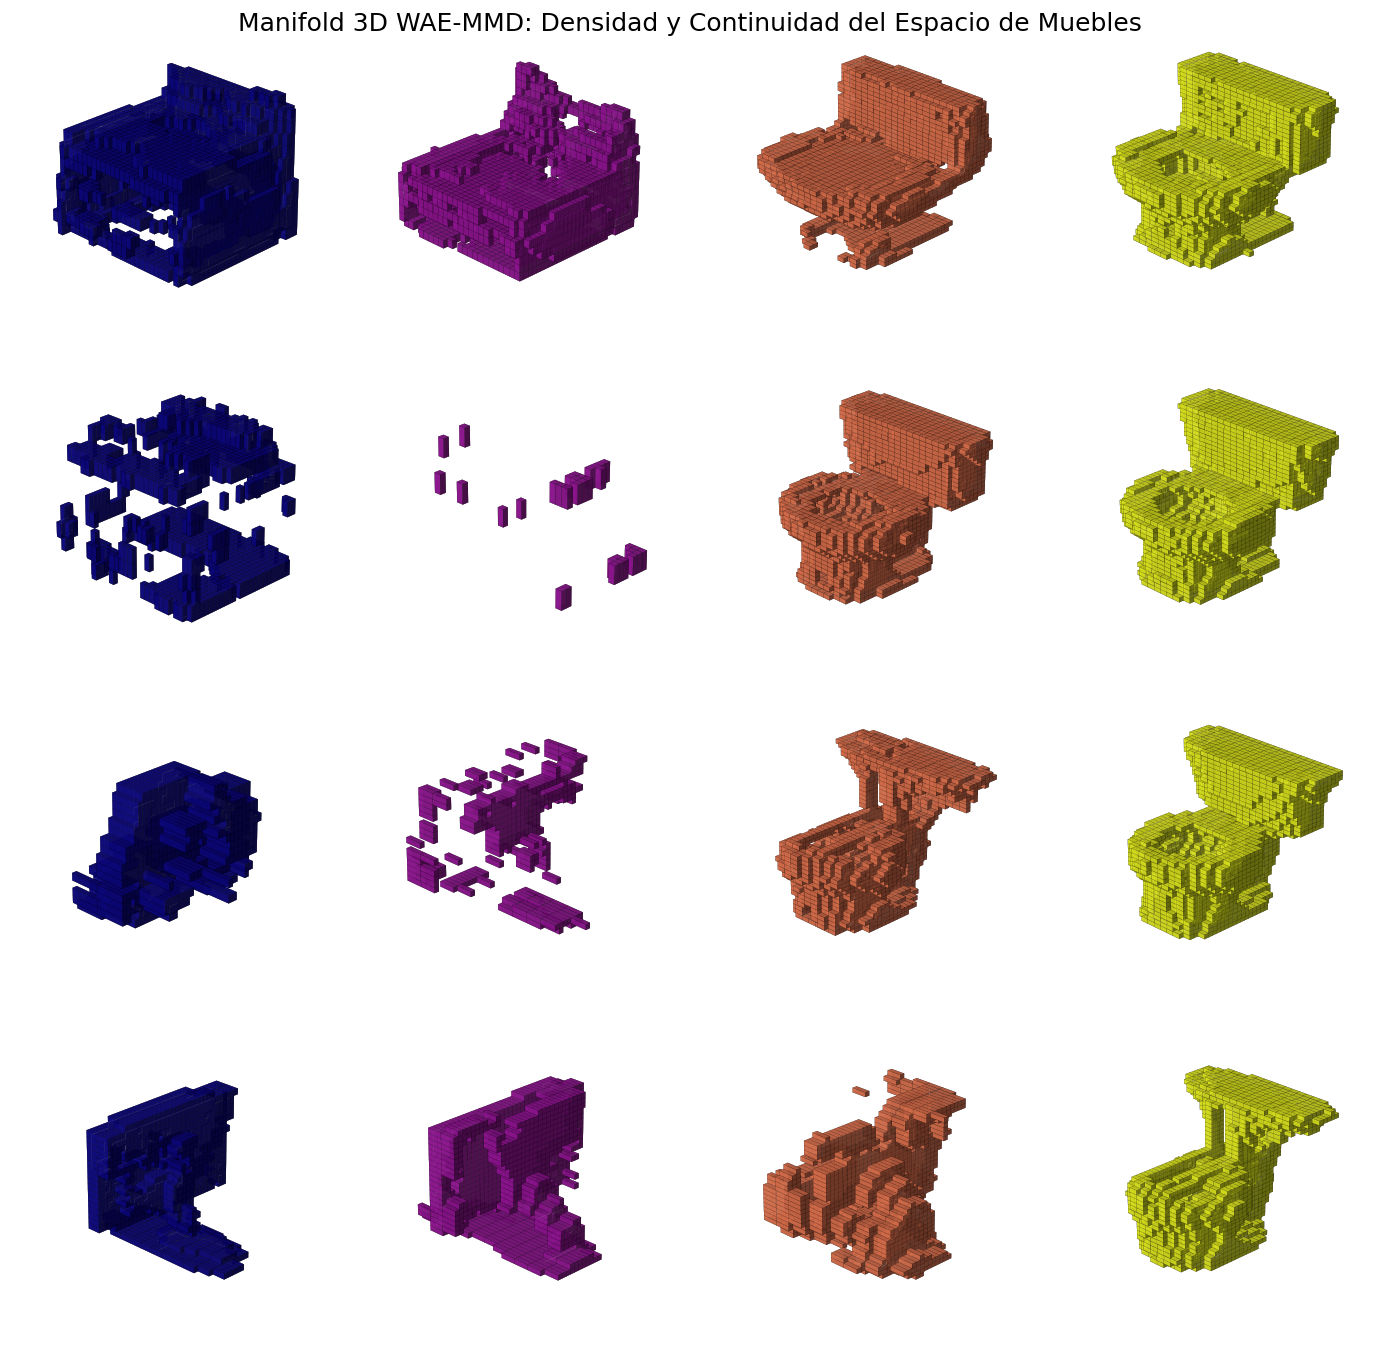

In [59]:
n_grid = 4

# Calculamos los límites basados en la dispersión real del WAE
min_x, max_x = np.percentile(z_test_2d_wae[:, 0], [5, 95])
min_y, max_y = np.percentile(z_test_2d_wae[:, 1], [5, 95])

grid_x = np.linspace(min_x, max_x, n_grid)
grid_y = np.linspace(min_y, max_y, n_grid)

fig = plt.figure(figsize=(14, 14))

contador = 1
for yi in grid_y:
    for xi in grid_x:
        punto_2d = np.array([[xi, yi]])
        
        # Reconstrucción inversa PCA e inferencia por el decoder
        z_256 = pca_wae.inverse_transform(punto_2d)
        mueble_generado = decoder_wae.predict(z_256, verbose=0)
        
        ax = fig.add_subplot(n_grid, n_grid, contador, projection='3d')
        voxel_gen = mueble_generado[0][:, :, :, 0] > 0.5
        
        # Color dinámico basado en la posición en la cuadrícula
        color = plt.cm.plasma((xi - min_x) / (max_x - min_x))
        
        ax.voxels(voxel_gen, facecolors=color, edgecolor='k', linewidth=0.08, alpha=0.85)
        ax.view_init(elev=25, azim=-45)
        ax.axis("off")
        
        contador += 1

plt.suptitle("Manifold 3D WAE-MMD: Densidad y Continuidad del Espacio de Muebles", fontsize=18, y=0.96)
plt.tight_layout()
plt.savefig("manifold_modelnet_mmd.png", dpi=300)
plt.show()